## Step 1: Import libraries

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

## Public Reference Data — KNBS

### Public reference data and source notes

- **KNBS CPI:** 24 monthly observations from October 2024 to September 2026. The October 2024–September 2025 observations are sourced from the KNBS October 2025 CPI report; October 2025–September 2026 are sourced from the KNBS September 2026 CPI report. The series is the national Overall Consumer Price Index, with February 2019 = 100.
- **CPI reuse note:** The September 2026 repository record identifies CC BY-NC 4.0. An item-level reuse licence for the October 2025 PDF has not been independently confirmed in this project documentation. KNBS is attributed and the compiled series is used for this non-commercial educational analysis; do not assume every source file has identical terms.
- **County population:** Selected 2019 county figures are from KNBS, *2019 Kenya Population and Housing Census, Volume I: Population by County and Sub-County*, Table 2.4, ISBN 978-9966-102-09-6. The PDF states: “All Rights Reserved. Extracts may be published if the source is duly acknowledged.” Acknowledge KNBS and the full publication details when presenting these extracts.
- The retail transactions, products, stores and customer records are synthetic. CPI and census figures are real public reference data used only for context.


## Step 2: Load the datasets

In [4]:
# Set project directory
PROJECT_DIR = Path.cwd().parent

RAW_DIR = PROJECT_DIR / 'data' / 'raw' / 'synthetic'
PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'

# Load cleaned sales data
sales_clean = pd.read_csv(PROCESSED_DIR / 'sales_lines_clean.csv',parse_dates=['transaction_date'])

# Load supporting datasets
transactions = pd.read_csv(RAW_DIR / 'transactions_synthetic.csv',parse_dates=['transaction_date'])

products = pd.read_csv(RAW_DIR / 'products_synthetic.csv')
stores = pd.read_csv(RAW_DIR / 'stores_synthetic.csv')

customers = pd.read_csv(RAW_DIR / 'customers_synthetic.csv',parse_dates=['registration_date', 'first_purchase_date'])

# Load KNBS public reference data

PUBLIC_DIR = PROJECT_DIR / 'data' / 'raw' / 'public'

cpi = pd.read_csv(PUBLIC_DIR / 'knbs_cpi_monthly_oct2024_sep2026.csv', parse_dates=['month'])

county_population = pd.read_csv(PUBLIC_DIR / 'knbs_2019_population_selected_counties.csv')

## Step 3: Inspect the datasets

In [5]:
datasets = {
    'Sales Lines': sales_clean,
    'Transactions': transactions,
    'Products': products,
    'Stores': stores,
    'Customers': customers
}

for name, data in datasets.items():
    print(f'\n{name}')
    print('Shape:', data.shape)
    print('Missing values:', data.isna().sum().sum())


Sales Lines
Shape: (175098, 22)
Missing values: 175062

Transactions
Shape: (80000, 8)
Missing values: 0

Products
Shape: (250, 7)
Missing values: 0

Stores
Shape: (8, 6)
Missing values: 0

Customers
Shape: (4000, 7)
Missing values: 0


## Step 3A: Data quality and relationship validation
In this section, I check the quality and consistency of all five datasets used in the project. I examine missing values, exact duplicates, duplicate identifiers and relationships between the datasets.

I also check for orphan records, which are records containing identifiers that do not exist in their corresponding reference tables.

In [6]:
# Define datasets and their expected unique identifiers

primary_keys = {
    'Sales Lines': ['transaction_id', 'line_number'],
    'Transactions': ['transaction_id'],
    'Products': ['product_id'],
    'Stores': ['store_id'],
    'Customers': ['customer_id']
}

# Collect data quality results
quality_results = []

for name, data in datasets.items():

    key_columns = primary_keys[name]

    quality_results.append({
        'Dataset': name,
        'Rows': len(data),
        'Columns': len(data.columns),
        'Missing Values': data.isna().sum().sum(),
        'Exact Duplicates': data.duplicated().sum(),
        'Duplicate Keys': data.duplicated(
            subset=key_columns
        ).sum(),
        'Missing Key Values': data[key_columns].isna().any(axis=1).sum()
    })

quality_report = pd.DataFrame(quality_results)

display(quality_report)

,Dataset,Rows,Columns,Missing Values,Exact Duplicates,Duplicate Keys,Missing Key Values
0,Sales Lines,175098,22,175062,0,0,0
1,Transactions,80000,8,0,0,0,0
2,Products,250,7,0,0,0,0
3,Stores,8,6,0,0,0,0
4,Customers,4000,7,0,0,0,0


In [7]:
# Function to standardise IDs for comparison
# This does not modify the original datasets.

def normalise_key(series):
    return (
        series.astype('string')
        .str.strip()
        .replace('', pd.NA)
    )


# Function to identify orphan records
def check_orphan_records(child, child_key, parent, parent_key):

    child_ids = normalise_key(child[child_key])
    parent_ids = set(normalise_key(parent[parent_key]).dropna())

    orphan_count = (child_ids.notna() & ~child_ids.isin(parent_ids)).sum()

    return int(orphan_count)


# Define relationships between datasets

relationships = [
    ('Sales Lines', sales_clean, 'transaction_id',
     'Transactions', transactions, 'transaction_id'),

    ('Sales Lines', sales_clean, 'product_id',
     'Products', products, 'product_id'),

    ('Sales Lines', sales_clean, 'store_id',
     'Stores', stores, 'store_id'),

    ('Sales Lines', sales_clean, 'customer_id',
     'Customers', customers, 'customer_id'),

    ('Transactions', transactions, 'store_id',
     'Stores', stores, 'store_id'),

    ('Transactions', transactions, 'customer_id',
     'Customers', customers, 'customer_id')
]


# Run relationship checks

orphan_results = []

for child_name, child, child_key, parent_name, parent, parent_key in relationships:

    orphan_count = check_orphan_records(
        child, child_key, parent, parent_key
    )

    orphan_results.append({
        'Child Dataset': child_name,
        'Child Key': child_key,
        'Parent Dataset': parent_name,
        'Parent Key': parent_key,
        'Orphan Records': orphan_count
    })


orphan_report = pd.DataFrame(orphan_results)

display(orphan_report)

,Child Dataset,Child Key,Parent Dataset,Parent Key,Orphan Records
0,Sales Lines,transaction_id,Transactions,transaction_id,0
1,Sales Lines,product_id,Products,product_id,0
2,Sales Lines,store_id,Stores,store_id,0
3,Sales Lines,customer_id,Customers,customer_id,0
4,Transactions,store_id,Stores,store_id,0
5,Transactions,customer_id,Customers,customer_id,0


## Step 4: Combine the datasets

In [8]:
# Prepare reference tables

store_lookup = stores.rename(columns={'county': 'store_county'})

customer_lookup = customers.rename(columns={'county': 'customer_county'})

# Merge product information
sales_eda = sales_clean.merge(
    products[['product_id', 'product_name', 'category', 'brand']],
    on='product_id',
    how='left',
    validate='many_to_one'
)

# Merge store information
sales_eda = sales_eda.merge(store_lookup[['store_id', 'store_name', 'store_county', 'region', 'store_type']],
    on='store_id',
    how='left',
    validate='many_to_one'
)

# Merge customer information, including first purchase date
sales_eda = sales_eda.merge(customer_lookup[['customer_id', 'customer_county', 'loyalty_tier', 'customer_status_at_window_start', 'first_purchase_date']],
    on='customer_id',
    how='left',
    validate='many_to_one'
)

# Verify merging results
print('Original sales records:', len(sales_clean))
print('Records after merging:', len(sales_eda))
print('Final columns:', len(sales_eda.columns))

# Check missing lookup information
lookup_columns = [
    'product_name',
    'category',
    'store_name',
    'store_county',
    'loyalty_tier',
    'first_purchase_date'
]

display(
    sales_eda[lookup_columns]
    .isna()
    .sum()
    .to_frame('missing_values')
)

display(sales_eda.head())

Original sales records: 175098
Records after merging: 175098
Final columns: 33


,missing_values
product_name,0
category,0
store_name,0
store_county,0
loyalty_tier,0
first_purchase_date,0


,transaction_id,line_number,transaction_date,store_id,customer_id,product_id,quantity,list_unit_price_kes,discount_pct,net_unit_price_kes,gross_sales_kes,net_sales_kes,unit_cost_kes,gross_profit_kes,promotion_id,transaction_status,is_synthetic,year,month,year_month,day_name,discount_group,product_name,category,brand,store_name,store_county,region,store_type,customer_county,loyalty_tier,customer_status_at_window_start,first_purchase_date
0,TX0000001,1,2025-01-10,ST005,C03186,SKU0165,1,"1,864.69",5,"1,771.46","1,864.69","1,771.46","1,403.23",368.23,NaN,SALE,True,2025,1,2025-01,Friday,Low (above 0 to 10%),Clothing Item 165,Clothing,Kipepeo,Mombasa Central,Mombasa,Kenya,Urban,Nakuru,Standard,observed_new,2025-04-22
1,TX0000001,2,2025-01-10,ST005,C03186,SKU0137,1,"5,030.84",10,"4,527.76","5,030.84","4,527.76","3,810.10",717.66,NaN,SALE,True,2025,1,2025-01,Friday,Low (above 0 to 10%),Food Item 137,Food & Grocery,Jirani,Mombasa Central,Mombasa,Kenya,Urban,Nakuru,Standard,observed_new,2025-04-22
2,TX0000001,3,2025-01-10,ST005,C03186,SKU0127,1,"6,213.56",0,"6,213.56","6,213.56","6,213.56","3,345.95","2,867.61",NaN,SALE,True,2025,1,2025-01,Friday,No discount,Baby Item 127,Baby Products,Imara,Mombasa Central,Mombasa,Kenya,Urban,Nakuru,Standard,observed_new,2025-04-22
3,TX0000001,4,2025-01-10,ST005,C03186,SKU0069,2,"6,242.04",5,"5,929.94","12,484.08","11,859.88","4,160.80","3,538.28",NaN,SALE,True,2025,1,2025-01,Friday,Low (above 0 to 10%),Clothing Item 069,Clothing,Kipepeo,Mombasa Central,Mombasa,Kenya,Urban,Nakuru,Standard,observed_new,2025-04-22
4,TX0000002,1,2025-12-21,ST004,C03906,SKU0214,1,"3,664.25",5,"3,481.04","3,664.25","3,481.04","1,806.68","1,674.36",NaN,SALE,True,2025,12,2025-12,Sunday,Low (above 0 to 10%),Stationery Item 214,Stationery,Milele,Nakuru Town,Nakuru,Kenya,Urban,Nakuru,Silver,pre_existing,2023-10-20


### First-purchase date

In [9]:
# Calculate each customer's first observed purchase
first_observed_purchase = (sales_eda[sales_eda['transaction_status'] == 'SALE']
    .groupby('customer_id', as_index=False)
    .agg(
        first_observed_purchase_date=(
            'transaction_date', 'min'
        )
    )
)

# Merge the derived date into the analysis dataset
sales_eda = sales_eda.merge(first_observed_purchase,
    on='customer_id',
    how='left',
    validate='many_to_one'
)

print(
    "Missing first observed purchase dates:",
    sales_eda['first_observed_purchase_date'].isna().sum()
)

display(
    sales_eda[
        ['customer_id', 'transaction_date',
         'first_purchase_date',
         'first_observed_purchase_date']
    ].head()
)

Missing first observed purchase dates: 0


,customer_id,transaction_date,first_purchase_date,first_observed_purchase_date
0,C03186,2025-01-10,2025-04-22,2024-10-09
1,C03186,2025-01-10,2025-04-22,2024-10-09
2,C03186,2025-01-10,2025-04-22,2024-10-09
3,C03186,2025-01-10,2025-04-22,2024-10-09
4,C03906,2025-12-21,2023-10-20,2024-11-03


**First-purchase date note:** `first_purchase_date` is retained from the synthetic customer table. The generated date can conflict with observed transaction dates because the generator assigned it separately. `first_observed_purchase_date` is therefore derived from each customer's earliest SALE record within the October 2024–September 2026 project window. It is the first purchase observed in this dataset, not necessarily the customer's lifetime first purchase.

## Step 5: Separate sales, returns and voids

In [10]:
sales_only = sales_eda[
    sales_eda['transaction_status'] == 'SALE'
].copy()

returns_only = sales_eda[
    sales_eda['transaction_status'] == 'RETURN'
].copy()

void_only = sales_eda[
    sales_eda['transaction_status'] == 'VOID'
].copy()

print('Sales lines:', len(sales_only))
print('Return lines:', len(returns_only))
print('Void lines:', len(void_only))

Sales lines: 168859
Return lines: 4430
Void lines: 1809


In [45]:
# Validate returns and voids

negative_qty = sales_eda['quantity'] < 0
is_return = sales_eda['transaction_status'] == 'RETURN'
is_void = sales_eda['transaction_status'] == 'VOID'

print("Negative quantities:", negative_qty.sum())
print("Return records:", is_return.sum())

print("Negative quantities not marked RETURN:",
      (negative_qty & ~is_return).sum())

print("Returns without negative quantities:",
      (is_return & ~negative_qty).sum())

print("Void records with non-zero sales:",
      (sales_eda.loc[is_void, 'net_sales_kes'] != 0).sum())

# Financial summary
sales_revenue = sales_only['net_sales_kes'].sum()
returns_value = returns_only['net_sales_kes'].sum()

net_revenue_after_returns = sales_revenue + returns_value

print(f"\nSales revenue: KSh {sales_revenue:,.2f}")
print(f"Returns value: KSh {returns_value:,.2f}")
print(f"Net revenue after returns: KSh {net_revenue_after_returns:,.2f}")

Negative quantities: 4430
Return records: 4430
Negative quantities not marked RETURN: 0
Returns without negative quantities: 0
Void records with non-zero sales: 0

Sales revenue: KSh 785,966,166.52
Returns value: KSh -20,402,751.14
Net revenue after returns: KSh 765,563,415.38


**Revenue treatment:** `SALE` records are used for the main sales-only trend and segment analyses. `RETURN` records carry negative quantities and values; the return-adjusted measure is calculated by adding the negative return value to SALE revenue. `VOID` records are excluded from revenue analysis. The validation above found 4,430 negative-quantity records, all marked `RETURN`, no RETURN records without negative quantities, and no VOID records with non-zero net sales.


# 3. EDA Section 1 — Sales distributions
## A. Descriptive statistics

In [11]:
# Summary statistics for sales records

sales_columns = [
    'quantity',
    'list_unit_price_kes',
    'discount_pct',
    'net_sales_kes',
    'gross_profit_kes'
]

display(
    sales_only[sales_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
quantity,"168,859.00",1.42,0.72,1.00,1.00,1.00,2.00,4.00
list_unit_price_kes,"168,859.00","3,371.09","1,728.00",190.95,"1,929.94","3,345.54","4,776.53","6,431.72"
discount_pct,"168,859.00",3.01,4.01,0.00,0.00,0.00,5.00,25.00
net_sales_kes,"168,859.00","4,654.57","3,585.62",171.85,"2,242.16","3,872.89","5,720.38","25,726.88"
gross_profit_kes,"168,859.00","1,644.13","1,414.99",55.68,701.69,"1,271.69","2,121.37","12,469.40"


## B. Distribution of net sales

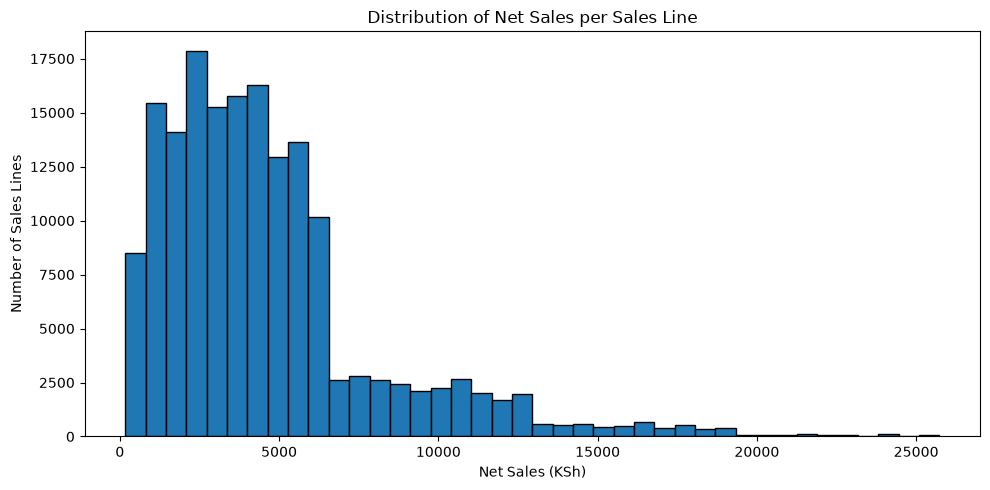

In [12]:
plt.figure(figsize=(10, 5))

plt.hist(
    sales_only['net_sales_kes'],
    bins=40,
    edgecolor='black'
)

plt.title('Distribution of Net Sales per Sales Line')
plt.xlabel('Net Sales (KSh)')
plt.ylabel('Number of Sales Lines')

plt.tight_layout()
plt.show()

## C. Distribution of gross profit

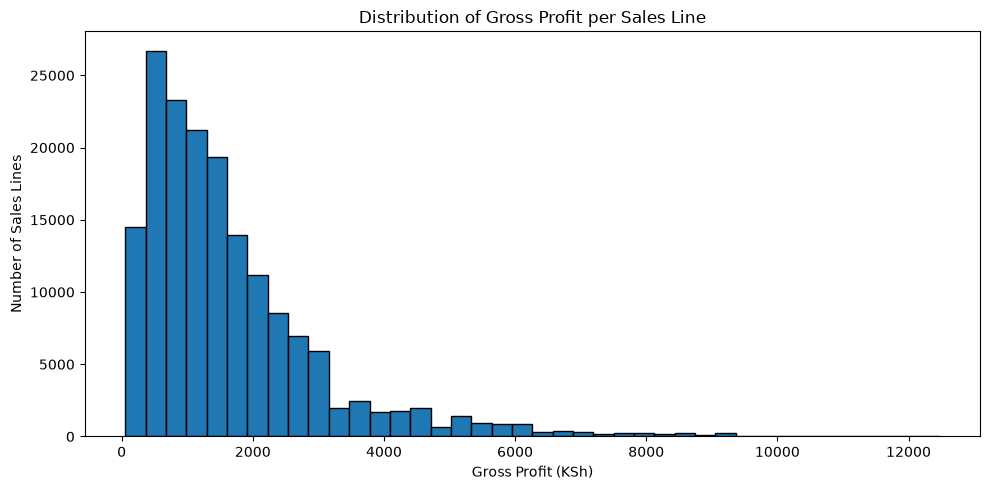

In [13]:
plt.figure(figsize=(10, 5))

plt.hist(
    sales_only['gross_profit_kes'],
    bins=40,
    edgecolor='black'
)

plt.title('Distribution of Gross Profit per Sales Line')
plt.xlabel('Gross Profit (KSh)')
plt.ylabel('Number of Sales Lines')

plt.tight_layout()
plt.show()

## D. Distribution of quantities sold

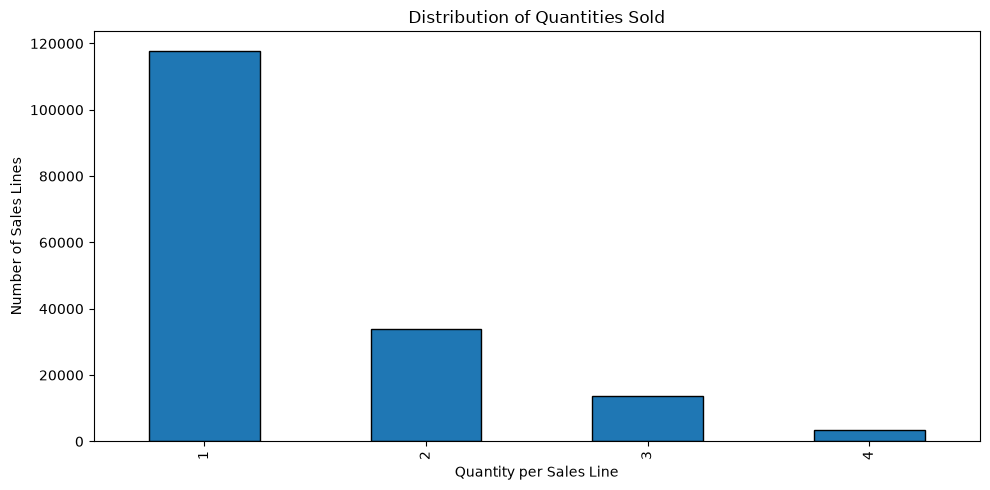

In [14]:
plt.figure(figsize=(10, 5))

sales_only['quantity'].value_counts().sort_index().plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Distribution of Quantities Sold')
plt.xlabel('Quantity per Sales Line')
plt.ylabel('Number of Sales Lines')

plt.tight_layout()
plt.show()

## E. Distribution of discounts

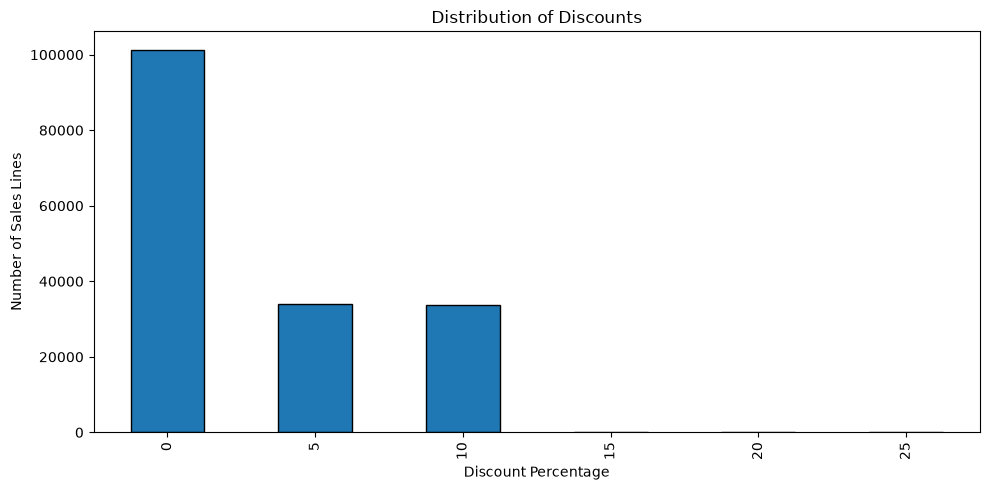

In [15]:
plt.figure(figsize=(10, 5))

sales_only['discount_pct'].value_counts().sort_index().plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Distribution of Discounts')
plt.xlabel('Discount Percentage')
plt.ylabel('Number of Sales Lines')

plt.tight_layout()
plt.show()

# 3. EDA Section 2 — Sales trends over time

## Step 1: Create monthly sales summary

In [16]:
# Group sales by month
monthly_sales = (sales_only.assign(month=sales_only['transaction_date'].dt.to_period('M')).groupby('month')
                 .agg(
                     revenue=('net_sales_kes', 'sum'),
                     gross_profit=('gross_profit_kes', 'sum'),
                     units_sold=('quantity', 'sum'),
                     sales_lines=('line_number', 'count'),
                     transactions=('transaction_id', 'nunique')
                 )
                 .reset_index()
)

# Convert month into date time for plotting

monthly_sales['month'] = monthly_sales['month'].dt.to_timestamp()
display(monthly_sales)

,month,revenue,gross_profit,units_sold,sales_lines,transactions
0,2024-10-01,"33,140,757.31","11,718,304.49",10219,7175,3304
1,2024-11-01,"33,023,987.47","11,621,384.97",10198,7183,3281
2,2024-12-01,"32,152,880.74","11,321,633.66",9655,6767,3088
3,2025-01-01,"32,665,547.51","11,638,791.79",9966,6997,3207
4,2025-02-01,"30,978,177.06","10,916,550.50",9430,6639,2981
5,2025-03-01,"33,637,549.73","11,776,033.65",10184,7119,3286
6,2025-04-01,"31,420,595.28","11,089,929.68",9588,6770,3075
7,2025-05-01,"31,405,685.26","11,058,065.55",9576,6787,3138
8,2025-06-01,"32,228,282.09","11,336,810.70",9940,6944,3213
9,2025-07-01,"34,155,868.76","12,010,627.29",10491,7366,3328


**Interpretation note:** The monthly revenue, gross-profit and units charts immediately below use `SALE` records only, so monthly revenue is before returns. The later CPI comparison uses `net_revenue_after_returns`, which includes the negative RETURN values. Keep this distinction in mind when comparing the two charts.

## Step 2: Plot monthly revenue

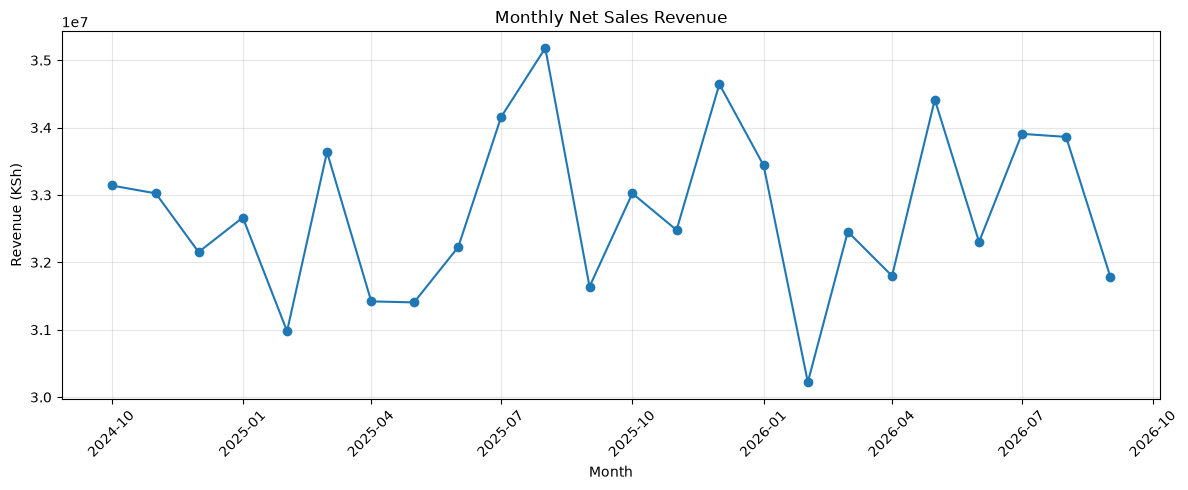

In [17]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales['month'], monthly_sales['revenue'], marker='o')

plt.title('Monthly Net Sales Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue (KSh)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Step 3: Plot monthly gross profit

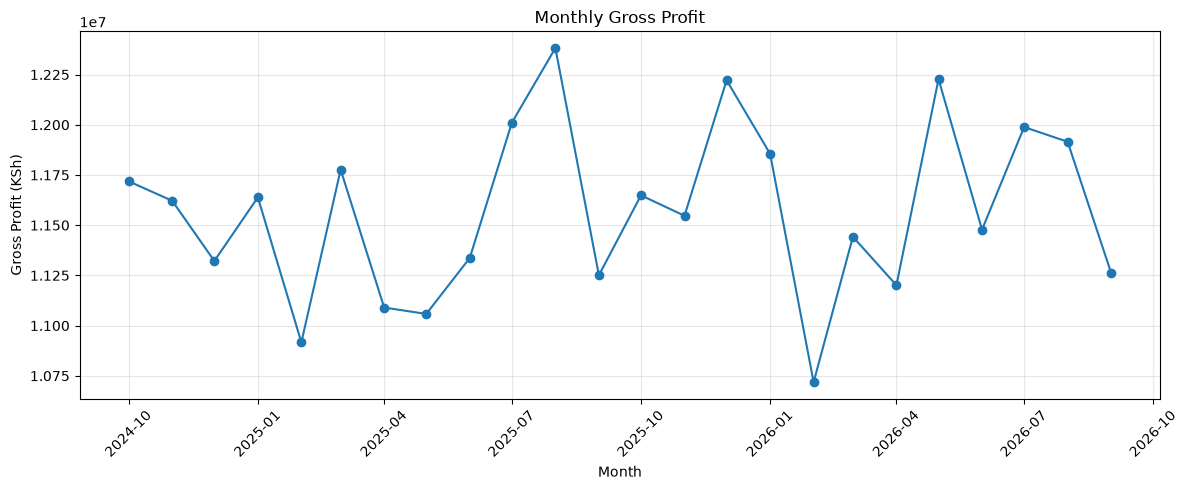

In [18]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales['month'], monthly_sales['gross_profit'], marker='o')

plt.title('Monthly Gross Profit')
plt.xlabel('Month')
plt.ylabel('Gross Profit (KSh)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Step 4: Plot monthly units sold

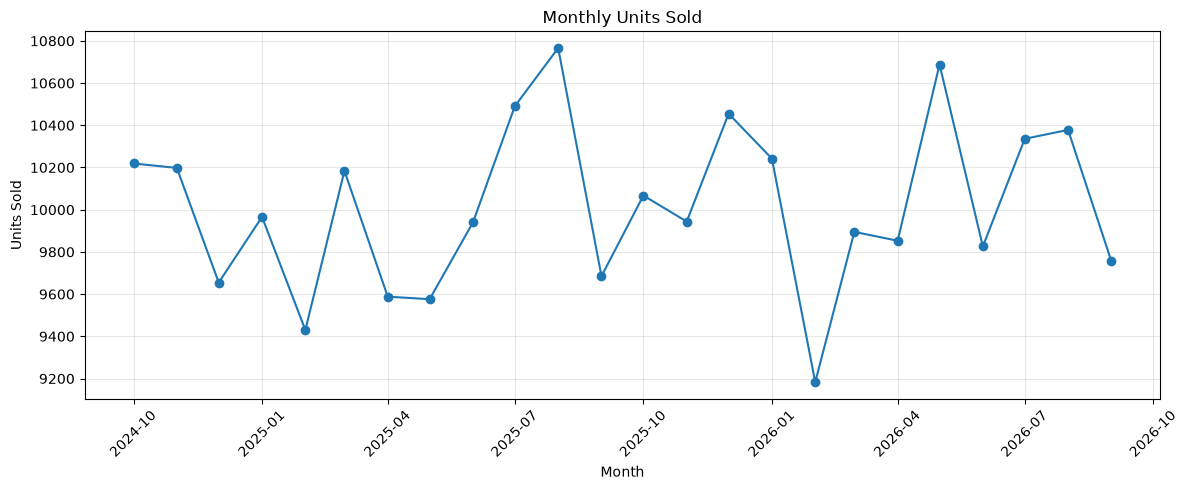

In [19]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales['month'], monthly_sales['units_sold'], marker='o')

plt.title('Monthly Units Sold')
plt.xlabel('Month')
plt.ylabel('Units Sold')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Step 5: Identify the strongest and weakest months

In [20]:
print('Top 5 Months by Revenue')

display(monthly_sales.nlargest(5, 'revenue')[['month', 'revenue', 'gross_profit', 'units_sold']])

print('Bottom 5 Months by Revenue')

display(monthly_sales.nsmallest(5, 'revenue')[['month', 'revenue', 'gross_profit', 'units_sold']])

Top 5 Months by Revenue


,month,revenue,gross_profit,units_sold
10,2025-08-01,"35,180,903.37","12,382,098.79",10766
14,2025-12-01,"34,645,055.28","12,221,636.87",10455
19,2026-05-01,"34,415,731.30","12,227,138.10",10688
9,2025-07-01,"34,155,868.76","12,010,627.29",10491
21,2026-07-01,"33,907,166.34","11,988,648.98",10336


Bottom 5 Months by Revenue


,month,revenue,gross_profit,units_sold
16,2026-02-01,"30,222,083.17","10,718,412.19",9183
4,2025-02-01,"30,978,177.06","10,916,550.50",9430
7,2025-05-01,"31,405,685.26","11,058,065.55",9576
6,2025-04-01,"31,420,595.28","11,089,929.68",9588
11,2025-09-01,"31,638,832.73","11,250,576.09",9685


### KNBS CPI and Monthly Sales Comparison

I compare the monthly sales trend with Kenya's Consumer Price Index (CPI) to provide economic context for the period October 2024 to September 2026.

The CPI is a national economic indicator and does not represent the retailer's actual selling prices. The comparison is descriptive and does not establish a causal relationship between inflation and sales.

Months analysed: 24
Missing CPI values: 0


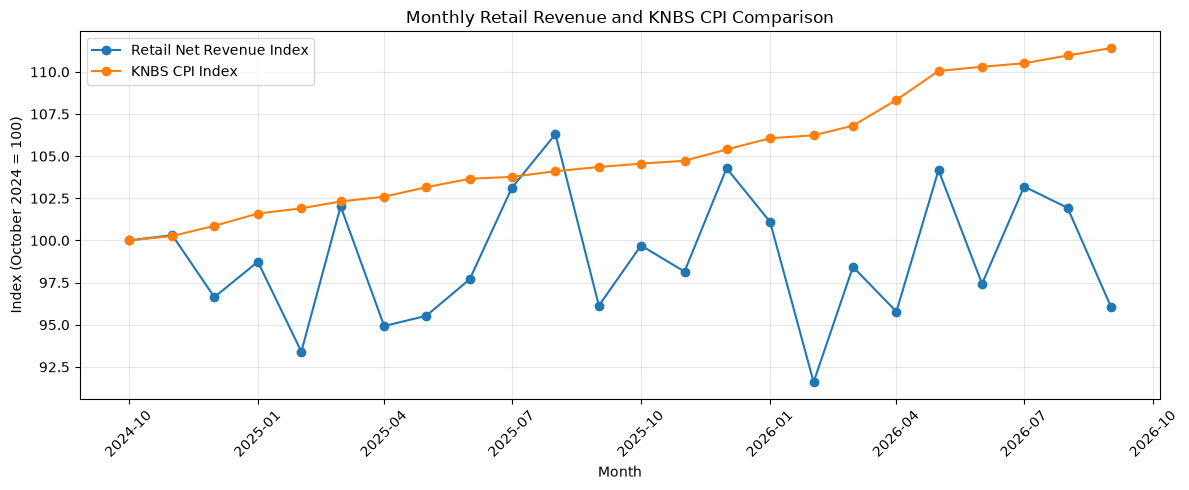

In [46]:
# Aggregate monthly returns
monthly_returns = (returns_only.assign(month=returns_only['transaction_date'].dt.to_period('M').dt.to_timestamp())
    .groupby('month')
    .agg(returns_value=('net_sales_kes', 'sum'))
    .reset_index()
)

# Combine sales revenue, returns and CPI
monthly_cpi_comparison = monthly_sales.merge(monthly_returns,on='month',how='left',validate='one_to_one')

monthly_cpi_comparison = monthly_cpi_comparison.merge(cpi[['month', 'overall_cpi_index']],on='month',
    how='left',
    validate='one_to_one'
)

# Months without returns are treated as zero returns
monthly_cpi_comparison['returns_value'] = (monthly_cpi_comparison['returns_value'].fillna(0))

# Calculate revenue after returns
monthly_cpi_comparison['net_revenue_after_returns'] = (monthly_cpi_comparison['revenue']+ monthly_cpi_comparison['returns_value'])

# Check the monthly matches
print("Months analysed:", len(monthly_cpi_comparison))
print("Missing CPI values:",monthly_cpi_comparison['overall_cpi_index'].isna().sum())

# Convert both measures to an index starting at 100
monthly_cpi_comparison = monthly_cpi_comparison.sort_values('month')

monthly_cpi_comparison['sales_index'] = (monthly_cpi_comparison['net_revenue_after_returns'] / monthly_cpi_comparison['net_revenue_after_returns'].iloc[0]) * 100

monthly_cpi_comparison['cpi_indexed'] = (monthly_cpi_comparison['overall_cpi_index'] / monthly_cpi_comparison['overall_cpi_index'].iloc[0]) * 100

# Plot comparison
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_cpi_comparison['month'],
    monthly_cpi_comparison['sales_index'],
    marker='o',
    label='Retail Net Revenue Index'
)

plt.plot(
    monthly_cpi_comparison['month'],
    monthly_cpi_comparison['cpi_indexed'],
    marker='o',
    label='KNBS CPI Index'
)

plt.title('Monthly Retail Revenue and KNBS CPI Comparison')
plt.xlabel('Month')
plt.ylabel('Index (October 2024 = 100)')
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# EDA Section 3 — Seasonality analysis

## Step 1: Prepare monthly seasonality summary

In [21]:
# Extract calendar month and name
monthly_sales['month_number'] = monthly_sales['month'].dt.month
monthly_sales['month_name'] = monthly_sales['month'].dt.strftime('%B')

# Calculate average performance for each calendar month
seasonal_summary = (monthly_sales.groupby(['month_number', 'month_name'])
                    .agg(
                        average_revenue=('revenue', 'mean'),
                        average_profit=('gross_profit', 'mean'),
                        average_units=('units_sold', 'mean'),
                        months_observed=('revenue', 'count')
                    ).reset_index().sort_values('month_number')
)

display(seasonal_summary)

,month_number,month_name,average_revenue,average_profit,average_units,months_observed
0,1,January,"33,052,013.30","11,747,124.25","10,104.00",2
1,2,February,"30,600,130.12","10,817,481.34","9,306.50",2
2,3,March,"33,046,147.66","11,609,061.04","10,039.50",2
3,4,April,"31,609,708.43","11,145,471.79","9,720.50",2
4,5,May,"32,910,708.28","11,642,601.82","10,132.00",2
5,6,June,"32,265,857.01","11,407,277.48","9,883.00",2
6,7,July,"34,031,517.55","11,999,638.13","10,413.50",2
7,8,August,"34,521,495.79","12,148,705.54","10,572.00",2
8,9,September,"31,712,514.59","11,256,389.88","9,720.50",2
9,10,October,"33,082,229.32","11,683,461.13","10,143.00",2


## Step 2: Plot average revenue by calendar month

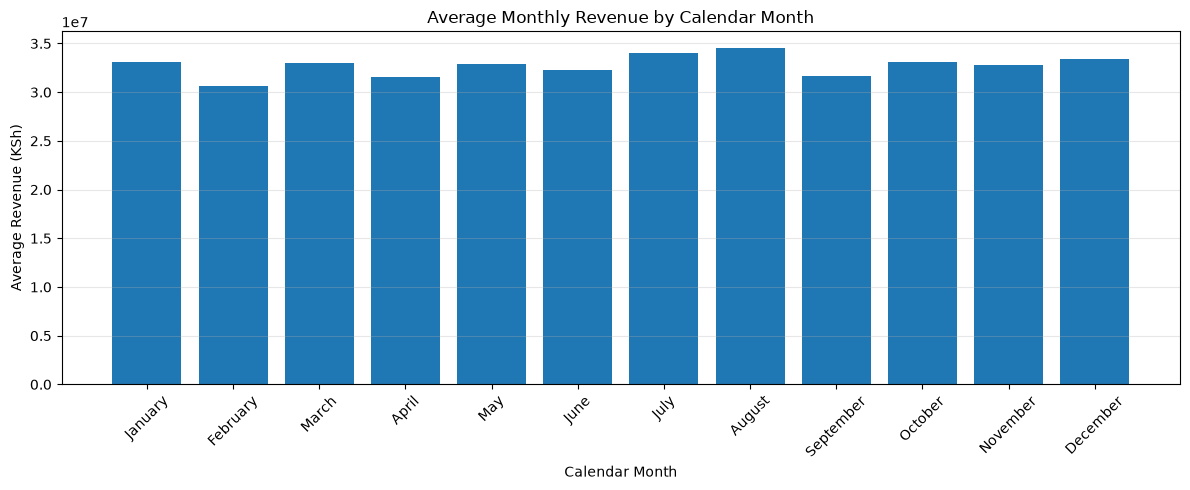

In [22]:
plt.figure(figsize=(12, 5))
plt.bar(seasonal_summary['month_name'], seasonal_summary['average_revenue'])

plt.title('Average Monthly Revenue by Calendar Month')
plt.xlabel('Calendar Month')
plt.ylabel('Average Revenue (KSh)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Step 3: Plot average gross profit by calendar month

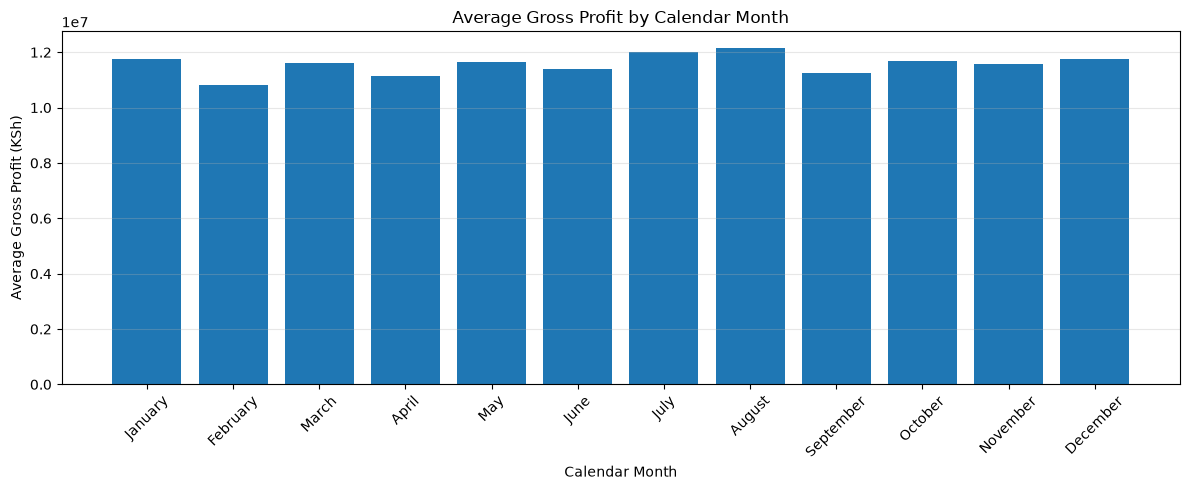

In [23]:
plt.figure(figsize=(12, 5))
plt.bar(seasonal_summary['month_name'], seasonal_summary['average_profit'])

plt.title('Average Gross Profit by Calendar Month')
plt.xlabel('Calendar Month')
plt.ylabel('Average Gross Profit (KSh)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


## Step 4: Compare January–September 2025 and 2026

In [24]:
# Create year and month fields
monthly_sales['year'] = monthly_sales['month'].dt.year

# Compare the first 9 months of 2025 and 2026
year_comparison = monthly_sales[(monthly_sales['year'].isin([2025, 2026])) & (monthly_sales['month_number']<=9)]

revenue_comparison = year_comparison.pivot(index='month_number', columns='year', values='revenue')

revenue_comparison['percentage_change'] = ((revenue_comparison[2026]/revenue_comparison[2025]) - 1) *100

display(revenue_comparison.round(2))


year,2025,2026,percentage_change
month_number,,,
1,"32,665,547.51","33,438,479.08",2.37
2,"30,978,177.06","30,222,083.17",-2.44
3,"33,637,549.73","32,454,745.59",-3.52
4,"31,420,595.28","31,798,821.57",1.20
5,"31,405,685.26","34,415,731.30",9.58
6,"32,228,282.09","32,303,431.92",0.23
7,"34,155,868.76","33,907,166.34",-0.73
8,"35,180,903.37","33,862,088.21",-3.75
9,"31,638,832.73","31,786,196.46",0.47


# EDA Section 4 — Store and county performance

## Step 1: Validate the merged information

In [25]:
display(sales_eda[['category', 'store_county', 'loyalty_tier']].isna().sum().to_frame('missing_values'))

,missing_values
category,0
store_county,0
loyalty_tier,0


## Step 2: Analyse performance by store

In [26]:
store_performance = (sales_only.groupby(['store_id', 'store_name', 'store_county'])
                     .agg(
                        revenue=('net_sales_kes', 'sum'),
                        gross_profit=('gross_profit_kes', 'sum'),
                        units_sold=('quantity', 'sum'),
                        sales_lines=('transaction_id', 'size'),
                        transactions=('transaction_id', 'nunique')
                     ).reset_index()
)

# Calculate gross profit margin
store_performance['gross_margin_pct'] = (store_performance['gross_profit']/store_performance['revenue']) *100

store_performance = store_performance.sort_values('revenue', ascending=False)

display(store_performance.round(2))

,store_id,store_name,store_county,revenue,gross_profit,units_sold,sales_lines,transactions,gross_margin_pct
1,ST002,Westlands,Nairobi,"100,927,730.95","35,614,875.63",30823,21594,9967,35.29
6,ST007,Kisumu Central,Kisumu,"99,338,122.08","35,055,397.10",30250,21355,9678,35.29
0,ST001,Nairobi CBD,Nairobi,"97,875,046.41","34,517,875.20",29941,21022,9611,35.27
2,ST003,Thika,Kiambu,"97,855,126.58","34,653,994.65",30004,21069,9623,35.41
5,ST006,Nyali,Mombasa,"97,835,335.88","34,519,495.91",30005,20963,9551,35.28
4,ST005,Mombasa Central,Mombasa,"97,481,792.45","34,499,457.38",29724,20918,9515,35.39
3,ST004,Nakuru Town,Nakuru,"97,378,760.95","34,384,210.19",29804,20964,9536,35.31
7,ST008,Eldoret,Uasin Gishu,"97,274,251.22","34,380,723.34",29770,20974,9645,35.34


## Step 3: Visualise revenue by store

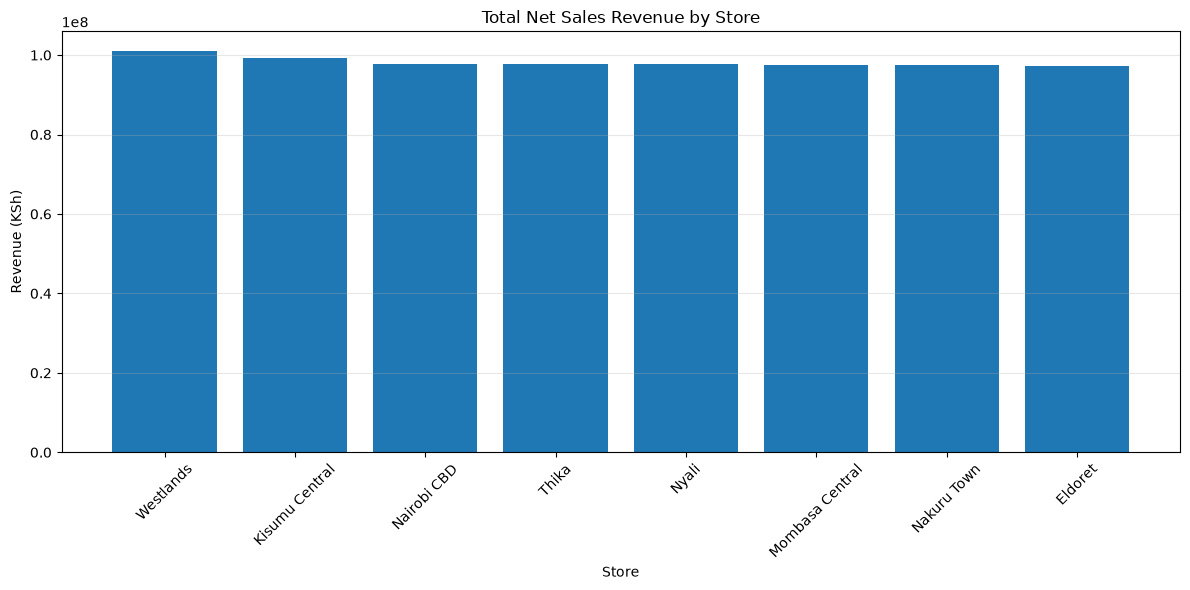

In [27]:
plt.figure(figsize=(12, 6))
plt.bar(store_performance['store_name'], store_performance['revenue'])

plt.title('Total Net Sales Revenue by Store')
plt.xlabel('Store')
plt.ylabel('Revenue (KSh)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Step 4: Visualise gross profit by store

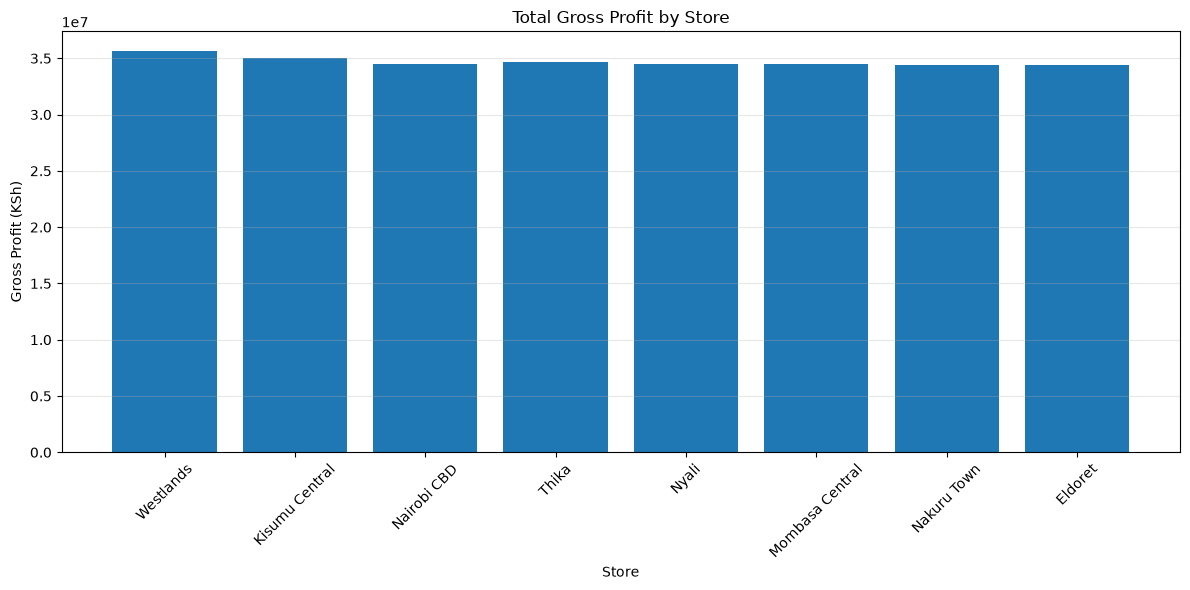

In [28]:
plt.figure(figsize=(12, 6))

plt.bar(store_performance['store_name'], store_performance['gross_profit'])
plt.title('Total Gross Profit by Store')
plt.xlabel('Store')
plt.ylabel('Gross Profit (KSh)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


## Step 5: Analyse county performance

In [29]:
county_performance = (sales_only.groupby('store_county')
                      .agg(
                          revenue=('net_sales_kes', 'sum'),
                          gross_profit=('gross_profit_kes', 'sum'),
                          units_sold=('quantity', 'sum'),
                          transactions=('transaction_id', 'nunique')    
                      ).reset_index().sort_values('revenue', ascending=False))

county_performance['gross_margin_pct'] = (county_performance['gross_profit'] / county_performance['revenue']) * 100

display(county_performance.round(2))

,store_county,revenue,gross_profit,units_sold,transactions,gross_margin_pct
3,Nairobi,"198,802,777.36","70,132,750.83",60764,19578,35.28
2,Mombasa,"195,317,128.33","69,018,953.29",59729,19066,35.34
1,Kisumu,"99,338,122.08","35,055,397.10",30250,9678,35.29
0,Kiambu,"97,855,126.58","34,653,994.65",30004,9623,35.41
4,Nakuru,"97,378,760.95","34,384,210.19",29804,9536,35.31
5,Uasin Gishu,"97,274,251.22","34,380,723.34",29770,9645,35.34


### Calculate the number of stores per county

In [47]:
# Count stores in each county

county_store_counts = (stores.groupby('county')
    .agg(number_of_stores=('store_id', 'nunique'))
    .reset_index()
    .rename(columns={'county': 'store_county'})
)

### Combine county performance and population

In [48]:
# Merge store counts and population information

county_analysis = county_performance.merge(county_store_counts,
    on='store_county',
    how='left')

county_analysis = county_analysis.merge(
    county_population[['store_county', 'population_2019','population_density_per_sq_km']],
    on='store_county',
    how='left',
    validate='one_to_one'
)

# Calculate average revenue per store
county_analysis['average_revenue_per_store'] = (county_analysis['revenue'] / county_analysis['number_of_stores'])

display(county_analysis.sort_values('average_revenue_per_store', ascending=False).round(2))

,store_county,revenue,gross_profit,units_sold,transactions,gross_margin_pct,number_of_stores,population_2019,population_density_per_sq_km,average_revenue_per_store
0,Nairobi,"198,802,777.36","70,132,750.83",60764,19578,35.28,2,4397073,6247,"99,401,388.68"
2,Kisumu,"99,338,122.08","35,055,397.10",30250,9678,35.29,1,1155574,554,"99,338,122.08"
3,Kiambu,"97,855,126.58","34,653,994.65",30004,9623,35.41,1,2417735,952,"97,855,126.58"
1,Mombasa,"195,317,128.33","69,018,953.29",59729,19066,35.34,2,1208333,5495,"97,658,564.16"
4,Nakuru,"97,378,760.95","34,384,210.19",29804,9536,35.31,1,2162202,290,"97,378,760.95"
5,Uasin Gishu,"97,274,251.22","34,380,723.34",29770,9645,35.34,1,1163186,343,"97,274,251.22"


### Visualise average revenue per store

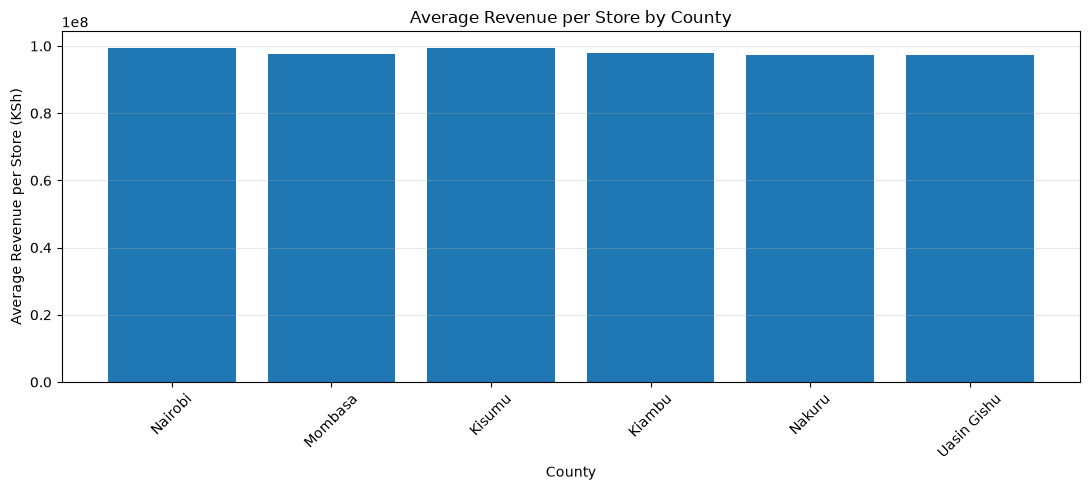

In [49]:
plt.figure(figsize=(11, 5))

plt.bar(county_analysis['store_county'], county_analysis['average_revenue_per_store'])

plt.title('Average Revenue per Store by County')
plt.xlabel('County')
plt.ylabel('Average Revenue per Store (KSh)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Step 6: Visualise revenue by county

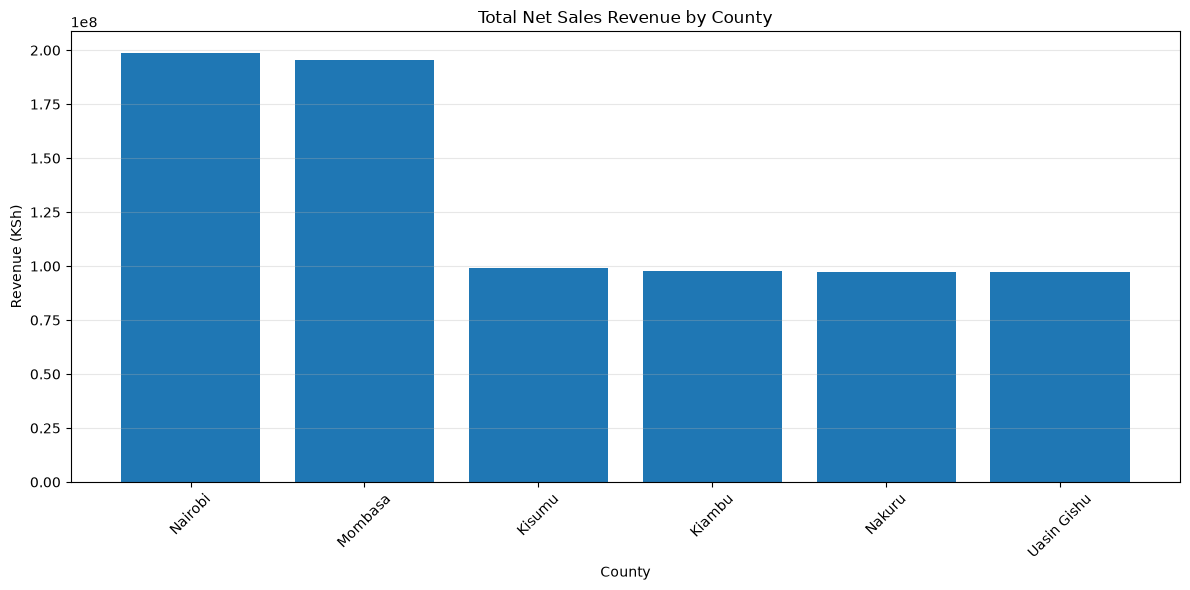

In [30]:
plt.figure(figsize=(12, 6))

plt.bar(county_performance['store_county'], county_performance['revenue'])
plt.title('Total Net Sales Revenue by County')
plt.xlabel('County')
plt.ylabel('Revenue (KSh)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


### County Performance and Population Context

The county analysis combines retail performance with 2019 KNBS
census population figures to provide additional geographical
context.

Nairobi recorded the highest total revenue at approximately
KSh 198.80 million, followed by Mombasa at KSh 195.32 million.
However, both counties have two stores, while the other counties
have one store each.

After calculating average revenue per store, Nairobi ranked
first at approximately KSh 99.40 million, followed closely
by Kisumu at KSh 99.34 million.

The average revenue per store was relatively consistent across
the six counties, with a difference of approximately 2.19%
between the highest and lowest results.

Population figures provide historical context but should not
be interpreted as actual market penetration because the retail
transactions and stores in this project are synthetic.
The population figures represent the 2019 census, not current
population estimates.

# EDA Section 5 — Product and category performance

## Step 1: Analyse product categories

In [31]:
category_performance = (sales_only.groupby('category')
                        .agg(
                            revenue=('net_sales_kes', 'sum'),
                            gross_profit=('gross_profit_kes', 'sum'),
                            units_sold=('quantity', 'sum'),
                            sales_lines=('product_id', 'size'),
                            products=('product_id', 'nunique'),
                            transactions=('transaction_id', 'nunique')
                        ).reset_index()
)

category_performance['gross_margin_pct'] = (category_performance['gross_profit'] / category_performance['revenue']) * 100

category_performance['revenue_share_pct'] = (category_performance['revenue'] / category_performance['revenue'].sum()) * 100

display(category_performance.round(2))

,category,revenue,gross_profit,units_sold,sales_lines,products,transactions,gross_margin_pct,revenue_share_pct
0,Baby Products,"80,916,205.90","29,215,617.18",29891,21053,31,18908,36.11,10.30
1,Clothing,"94,861,404.64","32,290,838.95",29632,20868,31,18722,34.04,12.07
2,Electronics,"94,689,925.13","37,453,511.33",29541,20662,31,18579,39.55,12.05
3,Food & Grocery,"122,126,615.29","39,386,243.04",30639,21554,32,19292,32.25,15.54
4,Home & Kitchen,"103,891,602.18","37,034,096.93",31032,21818,32,19485,35.65,13.22
5,Personal Care,"92,526,175.55","33,557,852.47",29688,20937,31,18779,36.27,11.77
6,Sports & Outdoors,"88,214,909.94","31,725,403.38",30098,21156,31,18984,35.96,11.22
7,Stationery,"108,739,327.89","36,962,466.12",29800,20811,31,18709,33.99,13.84


## Step 2: Plot revenue by category

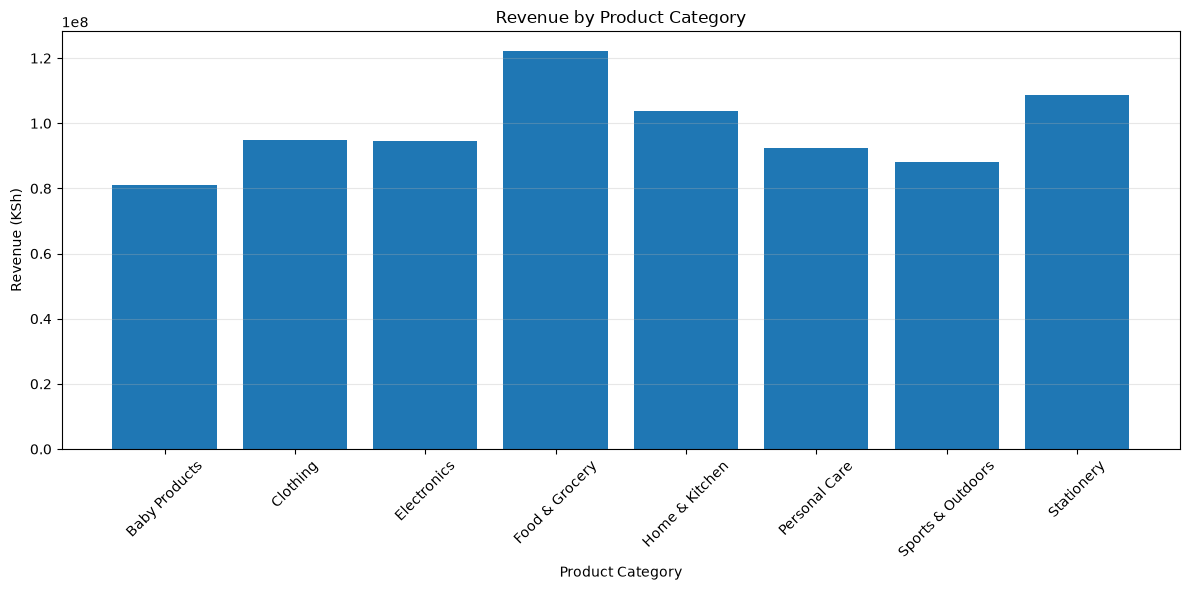

In [32]:
plt.figure(figsize=(12, 6))

plt.bar(category_performance['category'], category_performance['revenue'])
plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Revenue (KSh)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Step 3: Plot gross profit by category

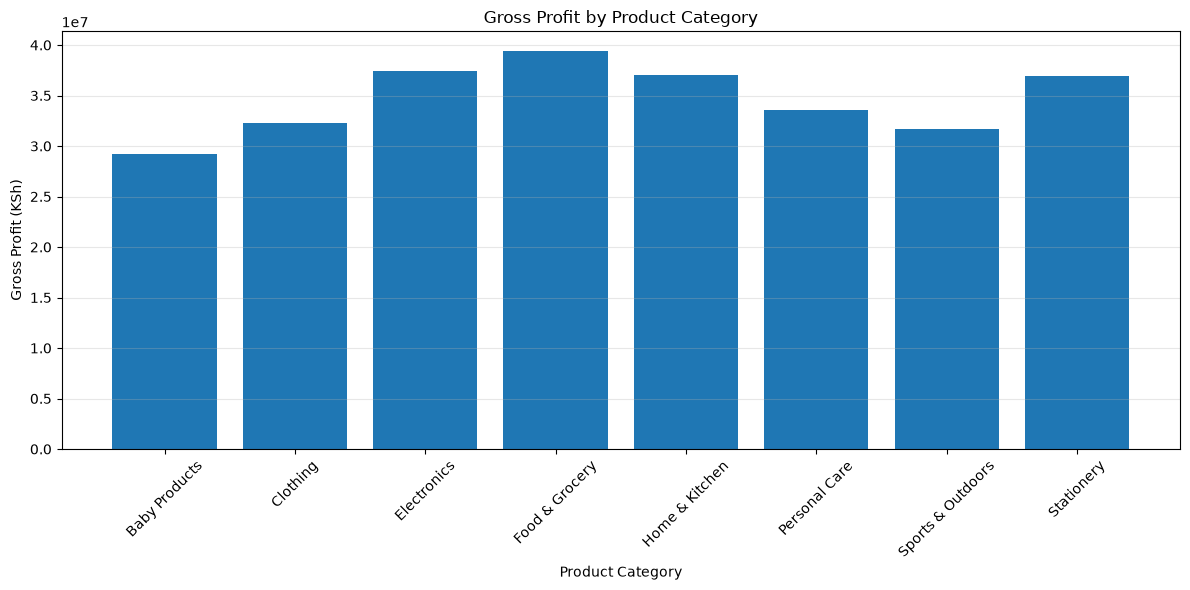

In [33]:
plt.figure(figsize=(12, 6))

plt.bar(category_performance['category'], category_performance['gross_profit'])
plt.title('Gross Profit by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Gross Profit (KSh)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Step 4: Identify the top 10 products by revenue

In [34]:
product_performance = (sales_only.groupby(['product_id', 'product_name', 'category'])
                       .agg(
                           revenue=('net_sales_kes', 'sum'),
                           gross_profit=('gross_profit_kes', 'sum'),
                           units_sold=('quantity', 'sum'),
                           sales_lines=('transaction_id', 'size')
                       ).reset_index())

product_performance['gross_margin_pct'] = (product_performance['gross_profit'] / product_performance['revenue']) * 100

top_products = product_performance.nlargest(10, 'revenue')

display(top_products.round(2))

,product_id,product_name,category,revenue,gross_profit,units_sold,sales_lines,gross_margin_pct
200,SKU0201,Food Item 201,Food & Grocery,"6,364,268.13","2,530,402.92",1021,722,39.76
64,SKU0065,Food Item 065,Food & Grocery,"6,181,919.92","1,640,965.08",1013,727,26.54
48,SKU0049,Food Item 049,Food & Grocery,"6,118,890.04","1,273,999.99",1001,695,20.82
166,SKU0167,Baby Item 167,Baby Products,"6,103,718.98","2,905,613.33",991,687,47.60
172,SKU0173,Clothing Item 173,Clothing,"5,997,766.26","1,559,752.50",971,673,26.01
24,SKU0025,Food Item 025,Food & Grocery,"5,938,863.11","2,015,668.52",963,662,33.94
104,SKU0105,Food Item 105,Food & Grocery,"5,916,129.67","1,479,504.97",954,682,25.01
126,SKU0127,Baby Item 127,Baby Products,"5,882,065.48","2,623,110.18",974,695,44.60
19,SKU0020,Electronics Item 020,Electronics,"5,853,620.58","2,680,181.25",993,684,45.79
188,SKU0189,Clothing Item 189,Clothing,"5,850,550.69","2,251,826.81",1003,694,38.49


## Step 5: Visualise the top 10 products

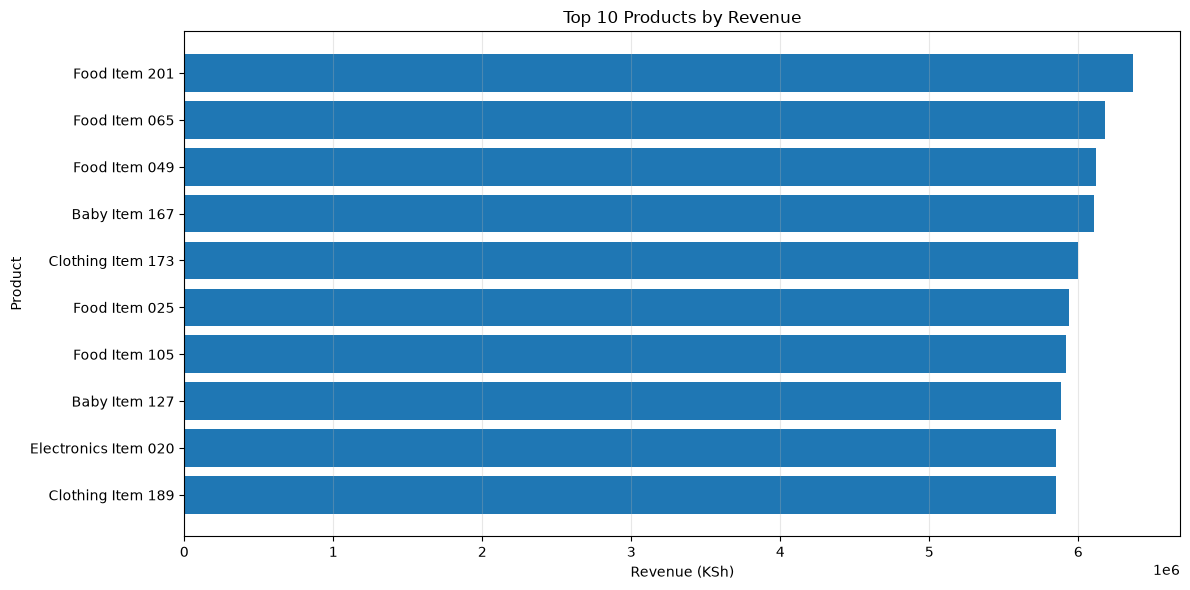

In [35]:
plt.figure(figsize=(12, 6))

plt.barh(top_products.sort_values('revenue')['product_name'], top_products.sort_values('revenue')['revenue'])

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (KSh)')
plt.ylabel('Product')
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# EDA Section 6 — Customer segments

## Step 1: Prepare customer-level performance

In [36]:
customer_performance = (sales_only.groupby(['customer_id', 'loyalty_tier', 'customer_status_at_window_start'])
                        .agg(
                            revenue=('net_sales_kes', 'sum'),
                            gross_profit=('gross_profit_kes', 'sum'),
                            units_sold=('quantity', 'sum'),
                            transactions=('transaction_id', 'nunique')
                        ).reset_index())

display(customer_performance.head())

,customer_id,loyalty_tier,customer_status_at_window_start,revenue,gross_profit,units_sold,transactions
0,C00001,Standard,observed_new,"266,616.29","98,993.05",80,22
1,C00002,Standard,observed_new,"198,450.40","68,274.22",54,21
2,C00003,Silver,observed_new,"214,180.37","75,023.78",73,24
3,C00004,Silver,observed_new,"262,404.32","93,641.49",85,23
4,C00005,Standard,observed_new,"185,093.27","65,431.01",56,21


## Step 2: Compare loyalty tiers

In [37]:
loyalty_performance = (customer_performance.groupby('loyalty_tier')
                       .agg(
                           purchasing_customers=('customer_id', 'nunique'),
                           revenue=('revenue', 'sum'),
                           gross_profit=('gross_profit', 'sum'),
                           average_revenue_per_customer=('revenue', 'mean'),
                           median_revenue_per_customer=('revenue', 'median'),
                           average_transactions_per_customer=('transactions', 'mean'),
                           units_sold=('units_sold', 'sum')
                       ).reset_index())

loyalty_performance['gross_margin_pct'] = (loyalty_performance['gross_profit'] / loyalty_performance['revenue']) * 100

display(loyalty_performance.sort_values('revenue', ascending=False).round(2))

,loyalty_tier,purchasing_customers,revenue,gross_profit,average_revenue_per_customer,median_revenue_per_customer,average_transactions_per_customer,units_sold,gross_margin_pct
2,Standard,2842,"557,735,795.46","196,958,144.27","196,247.64","193,018.83",19.23,170489,35.31
1,Silver,816,"160,586,870.52","56,698,303.46","196,797.64","192,865.42",19.41,49223,35.31
0,Gold,342,"67,643,500.54","23,969,581.67","197,788.01","195,734.60",19.36,20609,35.44


## Step 3: Visualise revenue by loyalty tier

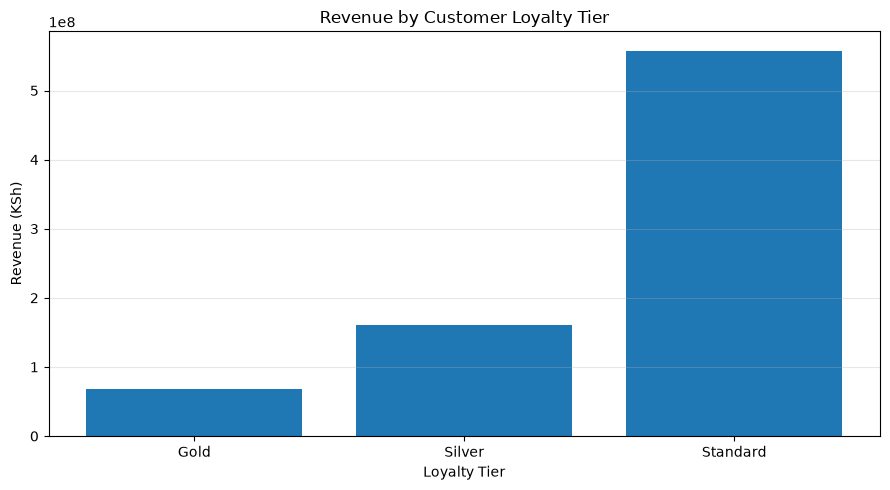

In [38]:
plt.figure(figsize=(9, 5))

plt.bar(loyalty_performance['loyalty_tier'], loyalty_performance['revenue'])
plt.title('Revenue by Customer Loyalty Tier')
plt.xlabel('Loyalty Tier')
plt.ylabel('Revenue (KSh)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Step 4: Compare customer status

In [39]:
customer_ststus_performance = (customer_performance.groupby('customer_status_at_window_start')
                               .agg(
                                   customers=('customer_id', 'nunique'),
                                   revenue=('revenue', 'sum'),
                                   gross_profit=('gross_profit', 'sum'),
                                   average_revenue_per_customer=('revenue', 'mean'),
                                   average_transactions_per_customer=('transactions', 'mean')   
                               ).reset_index())

display(customer_ststus_performance.round(2))

,customer_status_at_window_start,customers,revenue,gross_profit,average_revenue_per_customer,average_transactions_per_customer
0,observed_new,3274,"642,816,178.85","227,046,916.49","196,339.70",19.28
1,pre_existing,726,"143,149,987.67","50,579,112.91","197,176.29",19.29


## Step 5: Visualise average revenue per customer

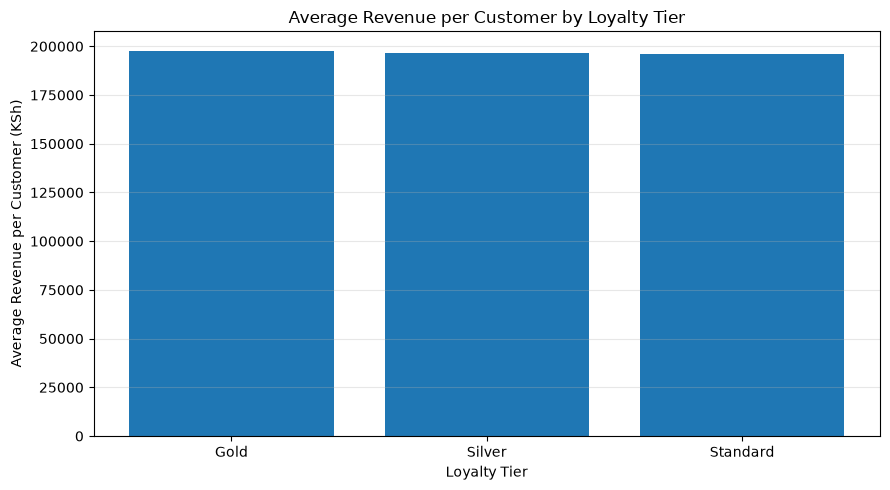

In [40]:
plt.figure(figsize=(9, 5))

plt.bar(loyalty_performance['loyalty_tier'], loyalty_performance['average_revenue_per_customer'])

plt.title('Average Revenue per Customer by Loyalty Tier')
plt.xlabel('Loyalty Tier')
plt.ylabel('Average Revenue per Customer (KSh)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# EDA Section 7 — Payment method analysis

## Step 1: Aggregate sales to transaction level

In [41]:
transaction_sales = (sales_only.groupby('transaction_id')
                     .agg(
                         basket_value=('net_sales_kes', 'sum'),
                         gross_profit=('gross_profit_kes', 'sum'),
                         units_sold=('quantity', 'sum'),
                         sales_lines=('line_number', 'count')    
                     ).reset_index())

# Add payment method from the transaction dataset
transaction_sales = transaction_sales.merge(transactions[['transaction_id', 'payment_method']], on = 'transaction_id',how='left', validate='one_to_one')

display(transaction_sales.head())

,transaction_id,basket_value,gross_profit,units_sold,sales_lines,payment_method
0,TX0000001,"24,372.66","7,491.78",5,4,Bank Transfer
1,TX0000002,"3,481.04","1,674.36",1,1,M-Pesa
2,TX0000003,"5,723.98","2,535.33",2,2,Card
3,TX0000004,"4,378.04","1,191.79",1,1,M-Pesa
4,TX0000005,"22,026.50","6,666.28",6,4,Card


## Step 2: Analyse payment methods

In [42]:
payment_performance =( transaction_sales.groupby('payment_method')
                      .agg(
                          transactions=('transaction_id', 'count'),
                          revenue=('basket_value', 'sum'),
                          gross_profit=('gross_profit', 'sum'),
                          average_basket_value=('basket_value', 'mean'),
                          average_units_per_transaction=('units_sold', 'mean')   
                      ).reset_index())

payment_performance['revenue_share_pct'] = (payment_performance['revenue'] / payment_performance['revenue'].sum()) * 100

payment_performance['gross_margin_pct'] = (payment_performance['gross_profit'] / payment_performance['revenue']) * 100

display(payment_performance.sort_values('revenue', ascending=False).round(2))

,payment_method,transactions,revenue,gross_profit,average_basket_value,average_units_per_transaction,revenue_share_pct,gross_margin_pct
3,M-Pesa,42989,"438,156,574.30","154,640,276.63","10,192.30",3.12,55.75,35.29
2,Cash,19453,"196,584,574.02","69,374,382.21","10,105.62",3.10,25.01,35.29
1,Card,10920,"112,649,283.27","39,979,918.24","10,315.87",3.14,14.33,35.49
0,Bank Transfer,3764,"38,575,734.93","13,631,452.32","10,248.60",3.13,4.91,35.34


## Step 3: Visualise revenue by payment method

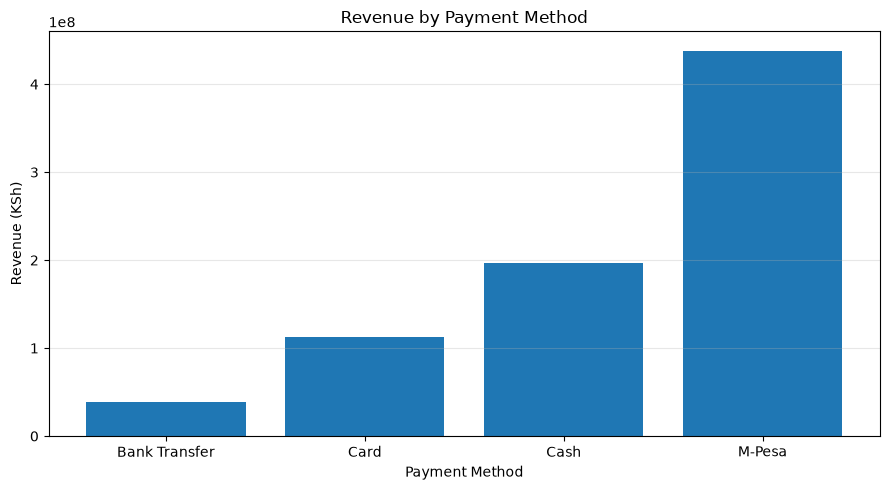

In [43]:
plt.figure(figsize=(9, 5))

plt.bar(payment_performance['payment_method'], payment_performance['revenue'])
plt.title('Revenue by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Revenue (KSh)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Step 4: Compare average basket values

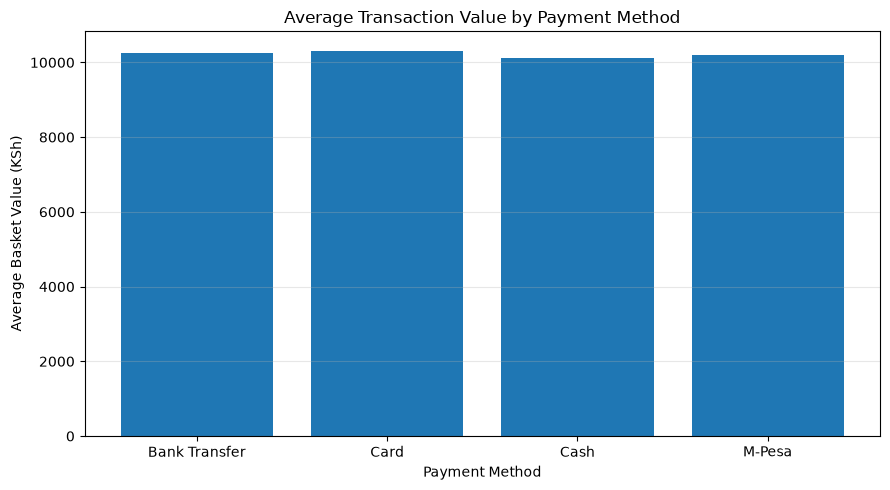

In [44]:
plt.figure(figsize=(9, 5))

plt.bar(payment_performance['payment_method'], payment_performance['average_basket_value'])
plt.title('Average Transaction Value by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Average Basket Value (KSh)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Final EDA Findings and Business Implications

The following five findings summarise the most important patterns observed in the synthetic retail dataset and the KNBS public reference data.

## 1. Sales lines are generally small-value, single-unit and often undiscounted

The median quantity per sales line was **1 unit** (mean 1.42; 75th percentile 2 units). The median discount was **0%**, and zero discount was the most frequently observed discount level. Net sales per line had a mean of approximately **KSh 4,654.57** and a median of **KSh 3,872.89**. This indicates that single-unit, non-discounted product lines are common in the generated dataset. Basket-level behaviour should be assessed separately because one receipt can contain several product lines.

**Business implication:** Monitor both product-line quantities and transaction-level basket size; do not interpret sales-line quantity as the total units bought by a customer.

## 2. Monthly retail revenue fluctuated while the national CPI rose

Average revenue was highest in **August** (approximately **KSh 34.52 million**) and lowest in **February** (approximately **KSh 30.60 million**) across the two observed years. The KNBS CPI increased from **140.44** in October 2024 to **156.47** in September 2026, an increase of approximately **11.4%**. Over the same period, the return-adjusted retail net revenue index ended at approximately **96.1** when October 2024 is set to 100.

**Business implication:** The differing movements make it useful to monitor sales volume and revenue alongside external price trends. The comparison is descriptive only; it does not establish that inflation caused the simulated sales movement.

## 3. Product categories differ in scale and profitability

**Food & Grocery** generated the highest category revenue (**KSh 122.13 million**, 15.54% of category revenue) and the highest gross profit (**KSh 39.39 million**). **Electronics** recorded the highest category gross margin at **39.55%**, while Food & Grocery had a 32.25% margin. Within the ten highest-revenue products, SKU0201 generated approximately **KSh 6.36 million** in revenue, while SKU0167 had the highest gross margin in that top-ten group at **47.60%**. SKU0049 generated approximately KSh 6.12 million but had a 20.82% margin.

**Business implication:** Merchandising decisions should consider revenue, unit volume and gross margin together rather than relying on revenue rankings alone.

## 4. Store performance was relatively consistent across the six counties

ST002 (Westlands) had the highest store revenue at approximately **KSh 100.93 million**, while ST008 (Eldoret) had the lowest at approximately **KSh 97.27 million**. Store gross margins ranged narrowly from about **35.27% to 35.41%**. After accounting for the number of stores in each county, average revenue per store ranged from approximately **KSh 97.27 million** in Uasin Gishu to **KSh 99.40 million** in Nairobi. Nairobi and Mombasa had two stores each; the other counties had one.

**Business implication:** Compare store-level performance and store counts before interpreting total county revenue. The 2019 population figures provide historical geographical context, not actual market penetration or current population estimates.

## 5. Customer-tier spend was similar, while M-Pesa contributed the largest payment share

Average revenue per purchasing customer was similar across loyalty tiers: approximately **KSh 196,248** for Standard, **KSh 196,798** for Silver and **KSh 197,788** for Gold customers. Average transactions per customer were also close (approximately 19.23–19.41). Standard customers generated the largest total revenue because they were the largest group. M-Pesa represented **55.75%** of sales revenue by payment method, followed by Cash (25.01%), Card (14.33%) and Bank Transfer (4.91%). Average basket values were relatively close across payment methods, from approximately **KSh 10,106 to KSh 10,316**.

**Business implication:** Total revenue by customer tier should be interpreted alongside group size and average spend. M-Pesa is the dominant payment channel in this dataset, but average basket value differs only modestly across payment methods.

## Limitations and interpretation cautions

- The business data (stores, customers, products, transactions, prices, costs and sales) is synthetic. Findings describe the generated dataset and must not be presented as actual Kenyan retailer performance.
- Transaction dates are generated across the observation window rather than from observed retail seasonality. The monthly peaks and troughs are descriptive patterns in the simulation, not evidence of real-world seasonal demand.
- The CPI is a national consumer price index, not the retailer's own selling-price index. CPI and sales comparisons do not demonstrate causation.
- County population figures are from the 2019 census. They are historical context and should not be treated as current population estimates or as a denominator for claims of actual market share.
- `first_observed_purchase_date` is the earliest SALE date recorded for a customer within this project's observation window; it is not necessarily a lifetime first-purchase date.
- The main monthly sales charts use SALE records only. The CPI comparison uses monthly net revenue after adding negative RETURN values. VOID records are excluded.
- The notebook analyses discount levels but does not provide a full causal or campaign-level evaluation of promotion effectiveness.

## Conclusion

This EDA examined sales distributions, monthly trends, seasonality patterns, store and county performance, product categories, customer loyalty tiers and payment methods. The analysis also incorporated KNBS CPI and 2019 county population data as external context. The findings provide a descriptive foundation for the next stages of the capstone, while the synthetic nature of the retail data and the limits of the public reference data are kept explicit.
